<a href="https://colab.research.google.com/github/owlmt/QML/blob/main/29_Adversarial_Robustness_Defences_for_QML/VQC_TransientStability_Yu2024.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# ReHELD variational circuit for robust power-system stability assessment: Yu and Zhou (2024) step by step

This notebook re-implements, runs and checks the method of

> Sijia Yu and Yifan Zhou, "Quantum Adversarial Machine Learning for Robust Power System Stability Assessment",
> 2024 IEEE Power & Energy Society General Meeting (PESGM), 2024. https://doi.org/10.1109/PESGM51994.2024.10688912

**What the notebook does.** A power system that is hit by a fault either rides through (it returns to a stable operating point) or it
loses synchronism. *Transient stability assessment* (TSA) predicts this from the post-fault state. The paper trains a *variational quantum
circuit* (the HELD circuit of its earlier work) as a TSA classifier (QTSA) and asks what happens when an attacker manipulates the **training
data**: a **data-deletion attack** (85 % of the training samples are removed) and a **data-poisoning attack** (Gaussian noise is added to
the whole training set). Its defence, **QaTSA**, uses the *ReHELD* circuit: a bounded non-linear data encoding `g(x) = sin(-x^T w)` plus an L2
regulariser on the variational angles (beta = 10, Eq. 16), both motivated by a Fourier-series view of the circuit (Eq. 14). Here we

1. regenerate the paper's test case, the single-machine infinite-bus (SMIB) system, by **time-domain simulation** (the stability label is the
   outcome of the simulation, nothing is invented), 2. apply the two attacks, 3. build HELD and ReHELD as real **PennyLane** circuits and train them
   with an exact state-vector simulator that is **asserted equal** to the PennyLane QNode, 4. check the Fourier-series claim numerically,
   5. compare with classical baselines (SVC, random forest, MLP) under the same attacks, 6. add one **extension that the paper does not contain**
   (a test-time FGSM evasion attack and adversarial training), and 7. compare every number with the paper.

**How to run it.** Open in Colab (badge above), choose a CPU runtime and use *Runtime -> Run all*. No GPU, no data download, no account and no
token are needed: the data are generated inside the notebook. The first cell installs a pinned PennyLane; if Colab asks you to restart the
session, do so and run all again.

**Runtime.** `FAST_MODE = True` (a 4-qubit, 5-layer circuit, 300 training states, 60 to 150 Adam steps per model) takes a few minutes on an idle laptop CPU; the committed run took about 25 minutes because the CPU was shared with many other jobs (the total is printed under the last cell). `FAST_MODE = False` uses the paper's circuit size (6 qubits, 15 layers, 500 training states) and epoch counts (1000 / 300 steps) that are listed in the configuration cell; on this shared machine that budget would have needed several hours, so **the committed outputs are from the `FAST_MODE = True` run** and the full path has not been executed.

**What you get at the end.** Plots of the generated stability data and of both attacked training sets, the drawn quantum circuits, training curves and learned
stability regions of HELD and ReHELD under each attack (the paper's Fig. 2-6), a numerical check of the Fourier-series claim, classical baselines, and a table that
puts the paper's numbers next to ours with a verdict per claim.

## The paper in one page

**Problem.** Data-driven transient stability assessment (TSA) learns the map `x -> y` from the post-fault state `x = [x_d(t_post), x_a(t_post)]`
(here for the SMIB system: rotor angle `delta` and rotor speed `omega`) to the label `y` in {stable, unstable}. A quantum model
`y = <0| U(x,p)^dagger M U(x,p) |0>` (Eq. 2) is a *variational quantum circuit* (VQC). Because the model is trained on data, an attacker who changes the training set changes the model.

**Attacks (Section II-B, V-A).** *Data deletion*: 85 % of the training samples are removed at random. *Data poisoning*: "20 % Gaussian noise" is added to the whole training set, so unstable samples end up inside the stability region and vice versa (Fig. 2).

**Circuit.** HELD (high expressibility, low depth) is a stack of `L` layers; layer `l` = data-encoding block E, variational block G, data re-encoding block R (Eq. 3-4). Spectral
decomposition of E and R shows the output is a Fourier-type sum `y(x) = sum_{t,j} alpha_{t,j} exp(i (Lambda_t - Lambda_j)^T x_hat)` (Eq. 14): the encoded data `x_hat = g(x)` set the available *frequencies*, the
variational block sets the *amplitudes* `alpha`. **ReHELD** (robustness-enhanced HELD) therefore (i) uses a bounded non-linear encoding `g(x) = sin(-x^T w)` so the encoded distribution has a small variance and a mean in [-1, 1], and (ii) adds
`beta * p^T p` to the cross-entropy loss (Eq. 16, beta = 10) to keep the amplitudes small.

**Data.** SMIB system (stability region known analytically, window `delta` in [-1, 4], `omega` in [0.96, 1.04] in the figures) and a 277-bus networked microgrid with 40 inverter-based resources (Fig. 7). Data sizes and system parameters are not stated.

**Claims we can check.**

| # | Claim | Paper value |
|---|---|---|
| C1 | HELD(1,1), linear encoding, SMIB, deletion attack (Fig. 3a) | 76.15 % test accuracy |
| C2 | ReHELD(1,1), non-linear encoding, same attack (Fig. 3b) | 90.04 % |
| C3 | Fig. 4: beta = 10 beats beta = 0 under poisoning | "nearly 4 %" better |
| C4 | Fig. 5: deletion attack, 6 qubits x 15 layers: HELD / ReHELD test accuracy, both train accuracies | ~95 % / ~98 %, train ~100 % |
| C5 | Fig. 6: poisoning attack, 6 x 15: HELD / ReHELD test accuracy; train accuracy falls below 80 % | ~95 % / ~98 % |
| C6 | Abstract: accuracy improvement of ReHELD over HELD | "18 % and 3 %" (= relative gains 76.15 -> 90.04 and ~95 -> ~98) |
| C7 | Eq. 14: the circuit output is a Fourier-type sum with frequencies set by the encoded data | theory (proof in paper) |
| C8 | Fig. 7: 8-microgrid, 277 buses, poisoning, ReHELD ~98 % | cannot be reproduced here (needs the reachable-dynamics model of ref. [10]) |

Training/test split sizes, circuit gates, optimiser, learning rate and the exact epoch counts are not given in the paper.

## What follows the paper and what had to be chosen

The paper is a four-page conference paper; it omits most implementation details (they live in the authors' earlier work, ref. [5]). Every choice below is marked `# CHOICE:` in the code.

| Item | Paper | This notebook |
|---|---|---|
| Test system | SMIB; 8-microgrid network (Fig. 7) | SMIB classical model (swing equation) only; the microgrid case cannot be regenerated (C8 "cannot be checked") |
| SMIB parameters | not stated | H = 3 s, 60 Hz, Pm = 0.5, Pmax = 1.0, damping D = 12 (all pu): CHOICE; delta window [-1, 4], omega window [0.96, 1.04] as in the figures |
| Data origin | simulation (stability region "analytically calculated") | regenerated from the paper's recipe: random post-fault states in the figure window, label = outcome of an RK4 time-domain simulation (stable iff the trajectory settles at the stable equilibrium); checked against the analytic energy-function bound |
| Dataset size | not stated | training pool 500 (FAST: 300), clean test set 1000 (FAST: 500): CHOICE |
| Deletion attack | random 85 % of the training samples deleted | identical |
| Poisoning attack | "20 % Gaussian noise across the entire training set" | additive Gaussian noise, std = 20 % of each feature's standard deviation, labels stay those of the unperturbed state: CHOICE (see section 2) |
| Test set under attack | not stated | clean (unattacked) test samples |
| Circuit layer | E G R blocks, details in ref. [5] | per layer and qubit: RY(g_r) (re-encoding), Rot (variational), ring of CNOTs, RX(g_e) (encoding); readout `<Z_0>`: CHOICE |
| Encoding g(x) | HELD linear, ReHELD `sin(-x^T w)`, `w` trainable | per qubit and block a trainable 2-vector `w`, no bias; inputs mapped to [-1, 1]^2 by a fixed linear map: CHOICE |
| Loss | cross-entropy + `beta p^T p`, beta = 10 | cross-entropy with `p = (1 + <Z_0>) / 2` plus `beta * mean(theta^2)` over the variational angles (block G only), beta = 10: CHOICE (a sum instead of a mean makes the penalty 270 times larger and dominates the loss) |
| Initialisation | not stated | encoding weights N(0, 1), variational angles uniform in [-0.5, 0.5] rad, identical for HELD and ReHELD: CHOICE |
| Optimiser | not stated | Adam, learning rate 0.05, full batch: CHOICE |
| Epochs | curves up to 1000 (deletion), 300 (poisoning), 200 (Fig. 4) | the same numbers in the full run; reduced in FAST_MODE |
| Circuit sizes | HELD(1,1), ReHELD(1,1), (6,15) | the same in the full run; FAST_MODE uses (4,5) as the "large" circuit |
| Classical baselines | none | SVC (RBF), random forest, MLP on identical inputs and attacked data |
| Seeds | not stated | several seeds, mean +- std over model initialisations and attack draws |

## 0. Setup

In [1]:
# Versions tested with this notebook (October 2026). Colab already ships torch, numpy, pandas, scikit-learn and matplotlib.
# The pip line runs on Colab (or wherever PennyLane is missing); a prepared local environment is left untouched.
import importlib.util, sys
IN_COLAB = importlib.util.find_spec("google.colab") is not None
if IN_COLAB or importlib.util.find_spec("pennylane") is None:
    %pip install -q "pennylane==0.45.1"
    if importlib.util.find_spec("torch") is None:
        %pip install -q torch --index-url https://download.pytorch.org/whl/cpu
    print("Packages installed. If Colab asks you to restart the session, do so and run all cells again.")
else:
    print("PennyLane already present; skipping pip install.")

PennyLane already present; skipping pip install.


The next cell holds **every tunable constant**. `FAST_MODE = True` is a few-minute class demo with a smaller circuit and fewer samples; `False` follows the paper's circuit size and
epoch counts as far as a CPU simulator allows (budgets in the comments). The paper does not state data sizes, optimiser or learning rate; those are `# CHOICE:` lines.

In [2]:
# ---------------- configuration ----------------
FAST_MODE = True          # True: class demo (a few minutes). False: the paper's circuit size and epoch counts.

SEED  = 42                  # data generation, attacks and model initialisation all derive from this
SEEDS_BIG   = [42]                                       # CHOICE: one repetition for the large circuit (expensive)
SEEDS_SMALL = [42, 43] if FAST_MODE else [42, 43, 44, 45, 46]   # CHOICE: repetitions for the 1-qubit circuits and the extension (cheap)
DATA_DIR = "data"           # unused: the data are generated, nothing is downloaded
IBM_TOKEN = ""              # unused: this paper has no hardware or noise experiment

# --- SMIB system (CHOICE: the paper gives no parameters; pu on a 60 Hz system) ---
H_INERTIA, F0, P_MECH, P_MAX, DAMPING = 3.0, 60.0, 0.5, 1.0, 12.0
DELTA_RANGE, OMEGA_RANGE = (-1.0, 4.0), (0.96, 1.04)      # the window of the paper's Fig. 2-6
T_SIM, DT_SIM = 15.0, 0.01                                # time-domain horizon and RK4 step

# --- data sizes (CHOICE) ---
N_TRAIN_POOL = 300 if FAST_MODE else 500     # clean training pool, before the attack
N_TEST       = 500 if FAST_MODE else 1000    # clean test set

# --- attacks (paper Section V-A) ---
DELETE_FRAC = 0.85          # data deletion: share of the training samples removed (paper: 85 %)
POISON_REL  = 0.20          # data poisoning: noise std as a share of each feature's std (paper: "20 % Gaussian noise")

# --- circuits (paper: HELD(m,n) / ReHELD(m,n) = m qubits, n layers) ---
SMALL_M, SMALL_L = 1, 1                                   # Fig. 3
BIG_M, BIG_L = (4, 5) if FAST_MODE else (6, 15)           # Fig. 4-6 (paper: 6 qubits, 15 layers)
BETA = 10.0                                               # paper Eq. 16

# --- optimisation (CHOICE: Adam, full batch) ---
LR = 0.05
EP_FIG3   = 150 if FAST_MODE else 300      # HELD(1,1) / ReHELD(1,1), deletion attack
EP_DELETE = 150 if FAST_MODE else 1000     # large circuit, deletion attack (paper Fig. 5: 1000 epochs)
EP_POISON = 100 if FAST_MODE else 300      # large circuit, poisoning attack (paper Fig. 6: 300 epochs; Fig. 4: 200)
EP_CLEAN  = 60  if FAST_MODE else 100      # reference without attack (one seed)
EP_EXT    = 60 if FAST_MODE else 100       # extension: FGSM / adversarial training
EXT_M, EXT_L = (2, 2) if FAST_MODE else (3, 3)           # CHOICE: small circuit for the extension (cost)
SEEDS_EXT = SEEDS_SMALL[:1] if FAST_MODE else SEEDS_SMALL[:3]
THETA_INIT = 0.5            # CHOICE: variational angles start uniformly in [-0.5, 0.5] rad (near-identity Rot gates), the same for HELD and ReHELD
EVAL_EVERY = 5 if FAST_MODE else 10       # test accuracy is evaluated every this many epochs
FGSM_EPS = 0.10                            # extension: L_inf budget in the [-1, 1] input scale (5 % of the span)

In [3]:
import os, time, math, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
warnings.filterwarnings("ignore", category=DeprecationWarning)
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

import torch
import pennylane as qml
import sklearn
from sklearn.decomposition import PCA
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import confusion_matrix, f1_score, precision_score, recall_score

torch.set_num_threads(2)
torch.manual_seed(SEED)
rng = np.random.default_rng(SEED)
pd.set_option("display.width", 220); pd.set_option("display.max_colwidth", 90); pd.set_option("display.max_columns", 30)
C_STABLE, C_UNSTABLE = "#2b6cb0", "#dd6b20"          # blue = stable, orange = unstable (colour-blind safe)
NOTEBOOK_T0 = time.time()
print("pennylane", qml.__version__, "| torch", torch.__version__, "| numpy", np.__version__, "| pandas", pd.__version__, "| scikit-learn", sklearn.__version__)
print("FAST_MODE =", FAST_MODE, "| big circuit =", (BIG_M, BIG_L), "| seeds big/small =", SEEDS_BIG, SEEDS_SMALL)

pennylane 0.45.1 | torch 2.14.1+cpu | numpy 2.5.4 | pandas 3.0.6 | scikit-learn 1.9.1
FAST_MODE = True | big circuit = (4, 5) | seeds big/small = [42] [42, 43]


## 1. The data: post-fault states of an SMIB system and their stability labels

The paper's test case is the **single-machine infinite-bus (SMIB)** system: one generator connected to an infinite grid. After a fault is cleared the rotor angle `delta` and the rotor speed `omega` (per unit,
1 = synchronous speed) evolve according to the swing equation

```
d delta / dt = w0 (omega - 1)                  (w0 = 2 pi 60 rad/s)
2 H d omega / dt = Pm - Pmax sin(delta) - D (omega - 1)
```

The post-fault state `x = [delta, omega]` at the fault-clearing time is the classifier input (this is the `x = [x_d(t_post), x_a(t_post)]` of Eq. 2). The label is whether the system **returns to its stable
equilibrium** `delta_s = asin(Pm / Pmax)` (stable) or loses synchronism and slips to another equilibrium or diverges (unstable). We obtain it by integrating the equations forward in time with the classical
4th-order Runge-Kutta method for 15 s, for 2-D states drawn uniformly in the window of the paper's figures. That is "time-domain simulation", the method the paper's introduction names as the reference TSA technique.

*Sanity check against theory.* For this damped system the energy `E = H w0 (omega - 1)^2 - Pm delta - Pmax cos(delta)` never increases along a trajectory, so every state whose energy is below the energy of the unstable
equilibrium (and that lies in the right valley) **must** be stable. The cell below asserts exactly this on the simulated labels; the same level set is the conservative analytic stability-region estimate drawn as a dashed line in the figures.

*No fitting happens in this section*: states are drawn from the physics, so there is nothing that could leak from test to training data. The linear map of `[delta, omega]` to `[-1, 1]^2` uses the known figure window, not training statistics.

In [4]:
# ---------------- SMIB simulator ----------------
W0 = 2 * np.pi * F0
DELTA_S = np.arcsin(P_MECH / P_MAX)            # stable equilibrium angle
DELTA_U = np.pi - DELTA_S                       # unstable equilibrium angle (saddle)

def _rhs(d, w):
    return W0 * (w - 1.0), (P_MECH - P_MAX * np.sin(d) - DAMPING * (w - 1.0)) / (2 * H_INERTIA)

def simulate_label(d0, w0_, T=T_SIM, dt=DT_SIM):
    # Vectorised RK4 over all initial states. Label 1 = stable: the trajectory ends at the stable equilibrium
    # (CHOICE of tolerance: |delta - delta_s| < 0.3 rad and |omega - 1| < 0.01 after T seconds).
    d, w = d0.astype(float).copy(), w0_.astype(float).copy()
    for _ in range(int(round(T / dt))):
        k1 = _rhs(d, w); k2 = _rhs(d + dt/2*k1[0], w + dt/2*k1[1]); k3 = _rhs(d + dt/2*k2[0], w + dt/2*k2[1]); k4 = _rhs(d + dt*k3[0], w + dt*k3[1])
        d = d + dt/6*(k1[0] + 2*k2[0] + 2*k3[0] + k4[0]); w = w + dt/6*(k1[1] + 2*k2[1] + 2*k3[1] + k4[1])
    return ((np.abs(d - DELTA_S) < 0.3) & (np.abs(w - 1) < 0.01)).astype(int)

def energy(d, w):
    return H_INERTIA * W0 * (w - 1.0)**2 - P_MECH * d - P_MAX * np.cos(d)

# left edge of the valley around delta_s: first delta < delta_s where the potential reaches the saddle energy
_grid = np.linspace(DELTA_S, -2 * np.pi, 200001)
E_U = energy(DELTA_U, 1.0)
DELTA_L = _grid[np.argmax(energy(_grid, 1.0) >= E_U)]
def inside_energy_region(d, w):
    return (energy(d, w) < E_U) & (d > DELTA_L) & (d < DELTA_U)

def sample_states(n, r):
    d = r.uniform(*DELTA_RANGE, n); w = r.uniform(*OMEGA_RANGE, n)
    return d, w, simulate_label(d, w)

def to_model_input(d, w):
    # CHOICE: fixed linear map of the figure window to [-1, 1]^2 (known design constants, not fitted on data)
    return np.stack([(d - np.mean(DELTA_RANGE)) / (np.ptp(DELTA_RANGE) / 2), (w - np.mean(OMEGA_RANGE)) / (np.ptp(OMEGA_RANGE) / 2)], 1)

def to_physical(X):
    return X[:, 0] * (np.ptp(DELTA_RANGE) / 2) + np.mean(DELTA_RANGE), X[:, 1] * (np.ptp(OMEGA_RANGE) / 2) + np.mean(OMEGA_RANGE)

t0 = time.time()
rng_data = np.random.default_rng(SEED)
d_tr, w_tr, y_tr = sample_states(N_TRAIN_POOL, rng_data)
d_te, w_te, y_te = sample_states(N_TEST, rng_data)
X_tr, X_te = to_model_input(d_tr, w_tr), to_model_input(d_te, w_te)
print(f"simulated {N_TRAIN_POOL + N_TEST} post-fault states in {time.time() - t0:.1f} s; stable share: train {y_tr.mean():.3f}, test {y_te.mean():.3f}")

# sanity check against theory: states under the saddle energy level must all be labelled stable
d_chk, w_chk, y_chk = sample_states(4000, np.random.default_rng(SEED + 99))
ins = inside_energy_region(d_chk, w_chk)
print(f"states inside the analytic energy-function region: {ins.sum()} of 4000, all labelled stable: {bool(y_chk[ins].all())}")
assert y_chk[ins].all(), "time-domain labels contradict the energy-function bound"
print(f"stable states outside that conservative region (the energy bound is only an inner estimate): {int((y_chk[~ins] == 1).sum())}")

simulated 800 post-fault states in 1.5 s; stable share: train 0.670, test 0.632


states inside the analytic energy-function region: 1149 of 4000, all labelled stable: True
stable states outside that conservative region (the energy bound is only an inner estimate): 1451


## 2. The two attacks

Both attacks act on the **training set only**; the test set stays clean, so test accuracy tells how much the attack damaged the learned stability region.

* **Data deletion** (paper: "randomly selecting 85 % of the training samples to delete"): keep a random 15 %.
* **Data poisoning** (paper: "introducing 20 % Gaussian noise across the entire training set"): the paper does not say how the 20 % is defined. `# CHOICE:` we add zero-mean Gaussian noise whose standard deviation is 20 % of each
  feature's standard deviation, and keep the labels of the *unperturbed* states. Stable and unstable samples then intermingle near the stability boundary, which is the picture of the paper's Fig. 2a. (The paper's Fig. 6 shows training accuracy below 80 % under poisoning, which a
  noise of this size does not produce: we measure and report the training accuracy and flag the difference in the final comparison.)

In [5]:
def delete_attack(X, y, frac, r):
    keep = r.choice(len(y), size=max(2, int(round(len(y) * (1 - frac)))), replace=False)
    return X[keep], y[keep]

def poison_attack(X, y, rel, r):
    sd = X.std(0, keepdims=True)                    # std of each feature of the (clean) training pool
    return X + r.normal(0.0, 1.0, X.shape) * rel * sd, y.copy()

rep = np.random.default_rng(SEED)
X_del, y_del = delete_attack(X_tr, y_tr, DELETE_FRAC, rep)
X_poi, y_poi = poison_attack(X_tr, y_tr, POISON_REL, rep)
print(f"clean pool {len(y_tr)} | after deletion {len(y_del)} (stable share {y_del.mean():.2f}) | after poisoning {len(y_poi)}")
# how much of the training labels does the noise scramble? agreement of the true stability rule (evaluated at the noisy states) with the kept labels
true_on_poison = simulate_label(*to_physical(X_poi))
print(f"share of poisoned training points whose label still agrees with the true stability rule: {(true_on_poison == y_poi).mean():.3f}"
      " (the best any classifier of the true region can score on the attacked training set)")

clean pool 300 | after deletion 45 (stable share 0.71) | after poisoning 300


share of poisoned training points whose label still agrees with the true stability rule: 0.923 (the best any classifier of the true region can score on the attacked training set)


## Dataset Exploration and Visualisation

Dataset: **SMIB post-fault states generated by time-domain simulation** (section 1). Each observation is a real simulated state `[delta, omega]` with the ground-truth label produced by the simulation; nothing is imputed or invented.
The data have a single binary label (stable / unstable), so there is no attack-family structure to colour by. The cells print the shape, feature names and class counts, plot the class distribution, and draw
(a) the physical plane with the analytic energy-function bound, (b) the PCA coordinates fitted on the training split, (c) the model inputs in `[-1, 1]^2`, and (d) the two attacked training sets (the paper's Fig. 2).

training pool X: (300, 2) | test X: (500, 2) | features: ['delta (rotor angle, rad)', 'omega (rotor speed, pu)']
original labels: 1 = stable (system returns to the equilibrium), 0 = unstable (loses synchronism)


,train,test
unstable (0),99,184
stable (1),201,316


,delta,omega,label
count,300.000,300.000,300.000
mean,1.433,1.000,0.670
std,1.452,0.023,0.471
min,-0.963,0.960,0.000
25%,0.136,0.982,0.000
50%,1.395,1.001,1.000
75%,2.755,1.020,1.000
max,3.962,1.040,1.000


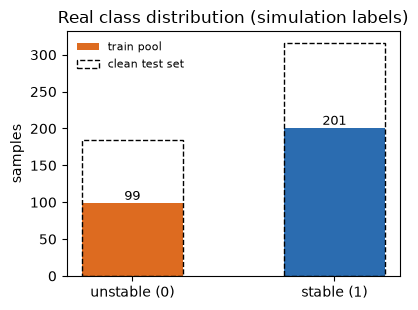

In [6]:
feat_names = ["delta (rotor angle, rad)", "omega (rotor speed, pu)"]
print("training pool X:", X_tr.shape, "| test X:", X_te.shape, "| features:", feat_names)
print("original labels: 1 = stable (system returns to the equilibrium), 0 = unstable (loses synchronism)")
counts = pd.DataFrame({"train": pd.Series(y_tr).value_counts().sort_index(), "test": pd.Series(y_te).value_counts().sort_index()})
counts.index = ["unstable (0)", "stable (1)"]; display(counts)
display(pd.DataFrame({"delta": d_tr, "omega": w_tr, "label": y_tr}).describe().round(3))

fig, ax = plt.subplots(figsize=(4.2, 3.2))
ax.bar(counts.index, counts["train"], color=[C_UNSTABLE, C_STABLE], width=0.5, label="train pool")
ax.bar(counts.index, counts["test"], color="none", edgecolor="black", width=0.5, linestyle="--", label="clean test set")
for i, v in enumerate(counts["train"]): ax.text(i, v, str(v), ha="center", va="bottom", fontsize=9)
ax.set_ylabel("samples"); ax.set_title("Real class distribution (simulation labels)"); ax.legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.show()

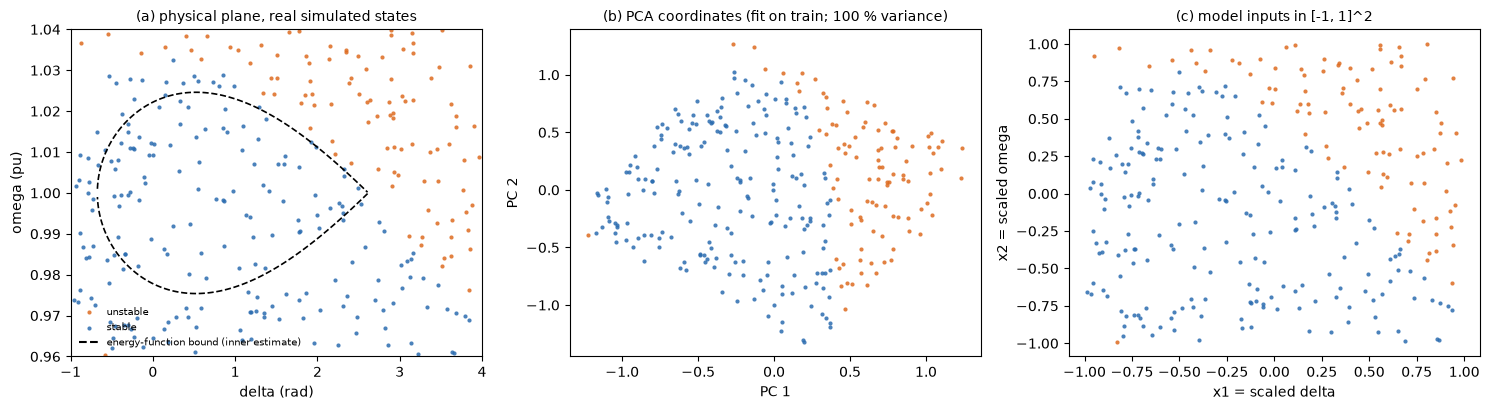

In [7]:
def energy_bound_contour(ax):
    dd, ww = np.meshgrid(np.linspace(*DELTA_RANGE, 400), np.linspace(*OMEGA_RANGE, 300))
    Ez = np.where((dd > DELTA_L) & (dd < DELTA_U), energy(dd, ww) - E_U, np.nan)
    ax.contour(dd, ww, Ez, levels=[0.0], colors="k", linestyles="--", linewidths=1.2)

def scatter_labels(ax, P, y, title, xl, yl, s=9, alpha=0.85):
    ax.scatter(P[y == 0, 0], P[y == 0, 1], s=s, c=C_UNSTABLE, alpha=alpha, label="unstable", linewidths=0)
    ax.scatter(P[y == 1, 0], P[y == 1, 1], s=s, c=C_STABLE, alpha=alpha, label="stable", linewidths=0)
    ax.set_title(title, fontsize=10); ax.set_xlabel(xl); ax.set_ylabel(yl)

pca = PCA(n_components=2, random_state=SEED).fit(X_tr)           # fitted on the training split only
P_tr = pca.transform(X_tr)
fig, axs = plt.subplots(1, 3, figsize=(15, 4.2))
scatter_labels(axs[0], np.c_[d_tr, w_tr], y_tr, "(a) physical plane, real simulated states", "delta (rad)", "omega (pu)")
energy_bound_contour(axs[0]); axs[0].plot([], [], "k--", label="energy-function bound (inner estimate)"); axs[0].legend(frameon=False, fontsize=7, loc="lower left")
scatter_labels(axs[1], P_tr, y_tr, f"(b) PCA coordinates (fit on train; {100*pca.explained_variance_ratio_.sum():.0f} % variance)", "PC 1", "PC 2")
scatter_labels(axs[2], X_tr, y_tr, "(c) model inputs in [-1, 1]^2", "x1 = scaled delta", "x2 = scaled omega")
plt.tight_layout(); plt.show()

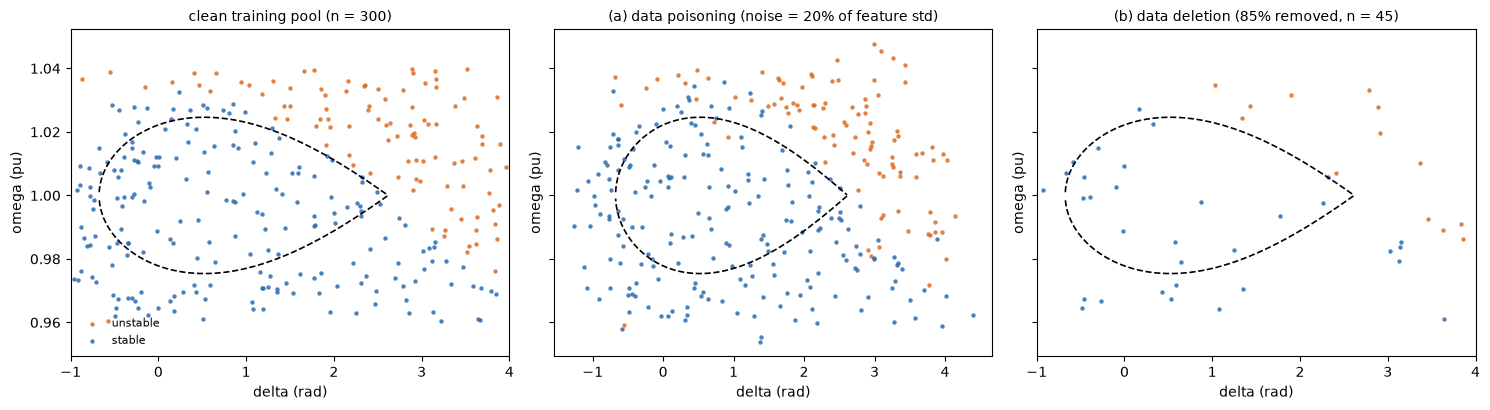

In [8]:
# the paper's Fig. 2: the same training pool under the two attacks (physical coordinates)
fig, axs = plt.subplots(1, 3, figsize=(15, 4.2), sharey=True)
for ax, (Xa, ya, ttl) in zip(axs, [(X_tr, y_tr, f"clean training pool (n = {len(y_tr)})"),
                                   (X_poi, y_poi, f"(a) data poisoning (noise = {POISON_REL:.0%} of feature std)"),
                                   (X_del, y_del, f"(b) data deletion ({DELETE_FRAC:.0%} removed, n = {len(y_del)})")]):
    dd, ww = to_physical(Xa); scatter_labels(ax, np.c_[dd, ww], ya, ttl, "delta (rad)", "omega (pu)", s=10); energy_bound_contour(ax)
axs[0].legend(frameon=False, fontsize=8, loc="lower left"); plt.tight_layout(); plt.show()

## 3. The HELD and ReHELD circuits

Layer `l` of HELD is `U(l) = E(l) G(l) R(l)` (Eq. 4): the right-most block `R` acts first. The paper takes the exact gates from its earlier work (ref. [5]), so the following is a `# CHOICE:` that respects Eq. 3-4 and the spectral argument of Section III:

| block | gate on every qubit `q` | parameters |
|---|---|---|
| R (re-encoding, first) | `RY( g(x; w_r[l,q]) )` | `w_r[l,q]` in R^2 |
| G (variational) | `Rot(phi, theta, omega)` on every qubit, then a ring of CNOTs `q -> q+1 mod m` (none for one qubit) | `theta[l,q]` in R^3 |
| E (encoding, last) | `RX( g(x; w_e[l,q]) )` | `w_e[l,q]` in R^2 |

Readout: `<Z_0>` on qubit 0, turned into a stability probability `p = (1 + <Z_0>) / 2`. The encoding function is **HELD: `g(x; w) = x^T w`** (linear) and **ReHELD: `g(x; w) = sin(-x^T w)`** (bounded, Section IV-A);
the trainable weights are different for every qubit, block and layer. A circuit with `m` qubits and `L` layers has `7 m L` trainable numbers (`4 m L` encoding weights and `3 m L` variational angles).
The ReHELD loss is `CE + beta * mean(theta^2)` (Eq. 16; `# CHOICE:` the penalty acts on block G only, as the paper's discussion of Fig. 4 says, and is normalised by the number of angles).

**Two implementations of the same circuit.** `qnode_factory` is the circuit as a PennyLane QNode (`default.qubit`, exact), which is what gets drawn and verified. Training thousands of optimisation steps through PennyLane's tape
machinery is slow on a CPU, so `forward_fast` is a hand-written batched PyTorch state-vector simulator that applies **the same gates** (the single-qubit gates of one layer are multiplied into one 2 x 2 matrix per qubit, the CNOT ring is one index permutation).
The next section asserts that `forward_fast` and the QNode agree to numerical precision, for random parameters and again for every trained model.

In [9]:
from functools import lru_cache

def _cd(x):  # complex dtype that matches the real dtype of the input
    return torch.complex64 if x.dtype == torch.float32 else torch.complex128

def ry_all(a, cd):
    c, s = torch.cos(a / 2), torch.sin(a / 2)
    return torch.stack([torch.stack([c, -s], -1), torch.stack([s, c], -1)], -2).to(cd)

def rx_all(a, cd):
    c, s = torch.cos(a / 2).to(cd), torch.sin(a / 2).to(cd)
    return torch.stack([torch.stack([c, -1j * s], -1), torch.stack([-1j * s, c], -1)], -2)

def rot_all(th, cd):                         # PennyLane Rot(phi, theta, omega) = RZ(omega) RY(theta) RZ(phi)
    phi, theta, omega = th[..., 0], th[..., 1], th[..., 2]
    c, s = torch.cos(theta / 2), torch.sin(theta / 2)
    e = lambda a: torch.exp(1j * a.to(cd))
    return torch.stack([torch.stack([e(-(phi + omega) / 2) * c, -e((phi - omega) / 2) * s], -1),
                        torch.stack([e(-(phi - omega) / 2) * s, e((phi + omega) / 2) * c], -1)], -2)

@lru_cache(maxsize=None)
def ring_index(m):
    # state_new = state[:, idx] after CNOT(0,1), CNOT(1,2), ..., CNOT(m-1,0) applied in this order (qubit 0 = most significant bit)
    idx = np.arange(2 ** m)
    for q in range(m):
        t = (q + 1) % m
        bc = (np.arange(2 ** m) >> (m - 1 - q)) & 1
        idx = idx[np.where(bc == 1, np.arange(2 ** m) ^ (1 << (m - 1 - t)), np.arange(2 ** m))]
    return torch.tensor(idx)

def apply1(state, U, q, m):
    B = state.shape[0]
    s = state.reshape(B, 2 ** q, 2, 2 ** (m - q - 1))
    if U.dim() == 2: U = U[None]
    s0, s1 = s[:, :, 0], s[:, :, 1]
    u = lambda i, j: U[:, i, j][:, None, None]
    return torch.stack([u(0, 0) * s0 + u(0, 1) * s1, u(1, 0) * s0 + u(1, 1) * s1], 2).reshape(B, 2 ** m)

def forward_fast(x, Wr, We, th, m, L, nonlinear):
    # <Z_0> of the HELD (nonlinear=False) or ReHELD (nonlinear=True) circuit for a batch x of shape (B, 2); exact state vector.
    B, cd = x.shape[0], _cd(x)
    ar = torch.einsum("bk,lqk->blq", x, Wr); ae = torch.einsum("bk,lqk->blq", x, We)      # x^T w for every block
    if nonlinear: ar, ae = torch.sin(-ar), torch.sin(-ae)                                  # ReHELD: g = sin(-x^T w)
    RY, RX, ROT = ry_all(ar, cd), rx_all(ae, cd), rot_all(th, cd)
    G = ROT[None] @ RY                                                                      # Rot . RY for every layer
    state = torch.zeros(B, 2 ** m, dtype=cd); state[:, 0] = 1
    for q in range(m): state = apply1(state, G[:, 0, q], q, m)                              # layer 1: R then G rotations
    for l in range(L):
        if m > 1: state = state[:, ring_index(m)]                                           # CNOT ring of block G
        for q in range(m):                                                                  # E of layer l fused with R and Rot of layer l+1
            U = RX[:, l, q] if l + 1 == L else G[:, l + 1, q] @ RX[:, l, q]
            state = apply1(state, U, q, m)
    pr = state.real ** 2 + state.imag ** 2
    h = 2 ** (m - 1)
    return pr[:, :h].sum(1) - pr[:, h:].sum(1)

def qnode_factory(m, L, nonlinear):
    # the same circuit as a real PennyLane QNode (exact, default.qubit)
    dev = qml.device("default.qubit", wires=m)
    @qml.qnode(dev, interface="torch", diff_method="backprop")
    def qnode(x, Wr, We, th):
        for l in range(L):
            for q in range(m):                                   # block R: re-encoding
                a = x @ Wr[l, q]
                qml.RY(torch.sin(-a) if nonlinear else a, wires=q)
            for q in range(m):                                   # block G: variational rotations ...
                qml.Rot(th[l, q, 0], th[l, q, 1], th[l, q, 2], wires=q)
            if m > 1:
                for q in range(m):                               # ... and CNOT ring
                    qml.CNOT(wires=[q, (q + 1) % m])
            for q in range(m):                                   # block E: encoding
                a = x @ We[l, q]
                qml.RX(torch.sin(-a) if nonlinear else a, wires=q)
        return qml.expval(qml.PauliZ(0))
    return qnode

def init_params(m, L, seed, dtype=torch.float32):
    # CHOICE: encoding weights ~ N(0, 1), variational angles ~ U(-THETA_INIT, THETA_INIT); identical for HELD and ReHELD.
    # A near-identity start keeps the beta * mean(theta^2) penalty small at step 0 and eases training of deep circuits.
    g = torch.Generator().manual_seed(seed)
    Wr = torch.randn(L, m, 2, generator=g, dtype=dtype); We = torch.randn(L, m, 2, generator=g, dtype=dtype)
    th = (torch.rand(L, m, 3, generator=g, dtype=dtype) * 2 - 1) * THETA_INIT
    return [Wr, We, th]
print("simulator and QNode defined")

simulator and QNode defined


## Quantum Circuit Architecture

Below are the circuits that are actually executed: the QNode objects drawn with `qml.draw_mpl`. There are three distinct architectures: **HELD(1,1)** (linear encoding), **ReHELD(1,1)** (the `sin(-x^T w)` encoding) and the large
**HELD / ReHELD(m,L)** (same gate sequence, different `g`; drawn for ReHELD). The angles printed on the encoding gates are the values for one example input state; the variational gates show their current (initial) angles. Qubit count, depth and the number of
trainable parameters are printed for every architecture. The large circuit is wide (`m` qubits x `L` layers), so it is shown twice: the first two layers at a readable size (same builder, `L = 2`) and the complete circuit in one very wide figure.

Matplotlib is building the font cache; this may take a moment.


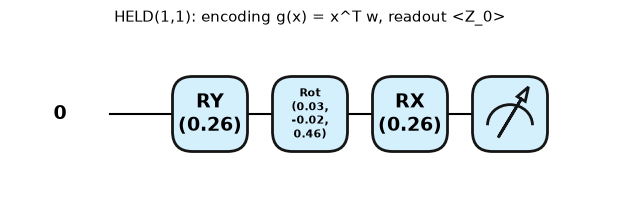

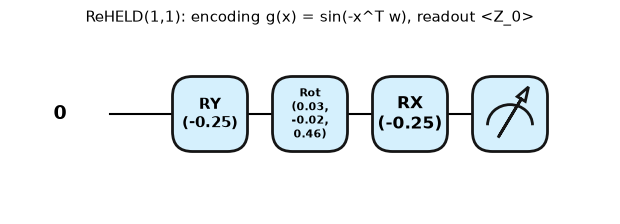

In [10]:
def circuit_stats(qnode, args, m, L):
    tape = qml.workflow.construct_tape(qnode)(*args)
    level = {}; depth = 0
    for op in tape.operations:
        lv = 1 + max(level.get(w, 0) for w in op.wires)
        for w in op.wires: level[w] = lv
        depth = max(depth, lv)
    names = pd.Series([op.name for op in tape.operations]).value_counts().to_dict()
    return dict(qubits=m, layers=L, depth=depth, gates=len(tape.operations), gate_counts=names,
                trainable_params=int(sum(p.numel() for p in args[1:])))

x_example = torch.tensor(X_tr[0], dtype=torch.float64)
arch_rows = []
for name, (m, L, nl) in {"HELD(1,1)": (SMALL_M, SMALL_L, False), "ReHELD(1,1)": (SMALL_M, SMALL_L, True)}.items():
    P = init_params(m, L, SEED, torch.float64); qn = qnode_factory(m, L, nl)
    fig, ax = qml.draw_mpl(qn, decimals=2, style="pennylane")(x_example, *P)
    fig.suptitle(f"{name}: encoding g(x) = {'sin(-x^T w)' if nl else 'x^T w'}, readout <Z_0>", y=1.02, fontsize=11); plt.show()
    arch_rows.append(dict(architecture=name, **circuit_stats(qn, (x_example, *P), m, L)))

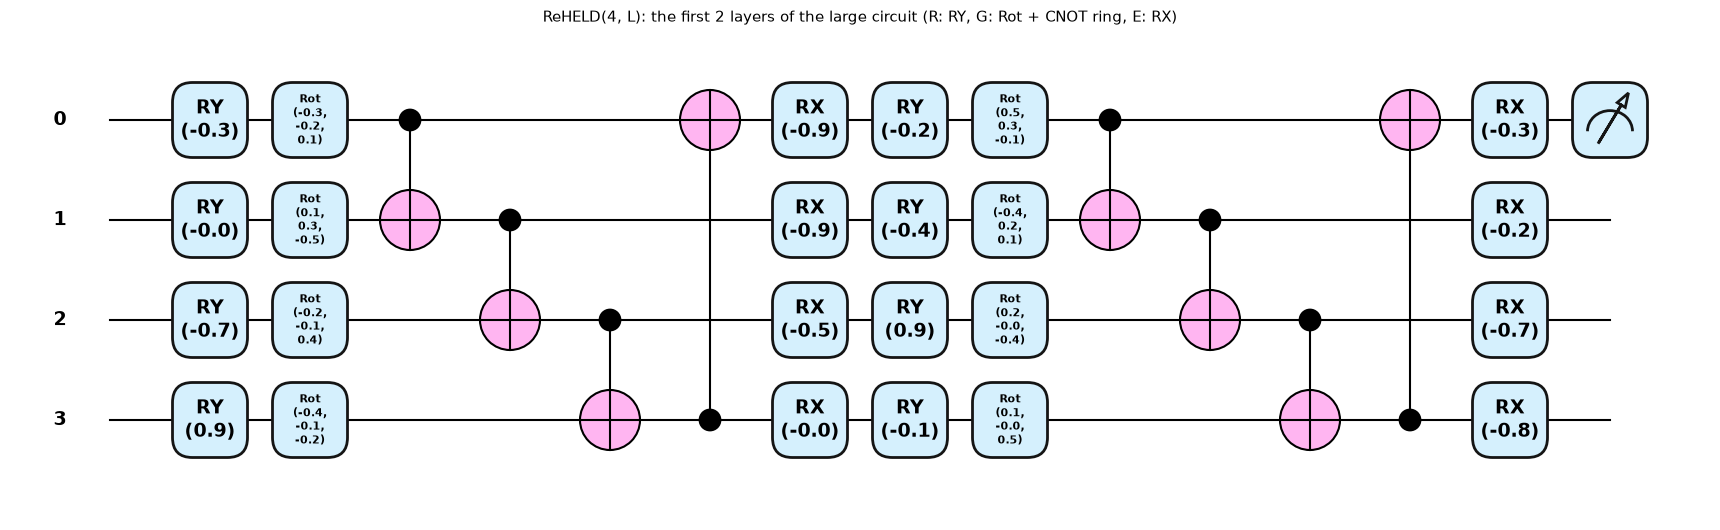

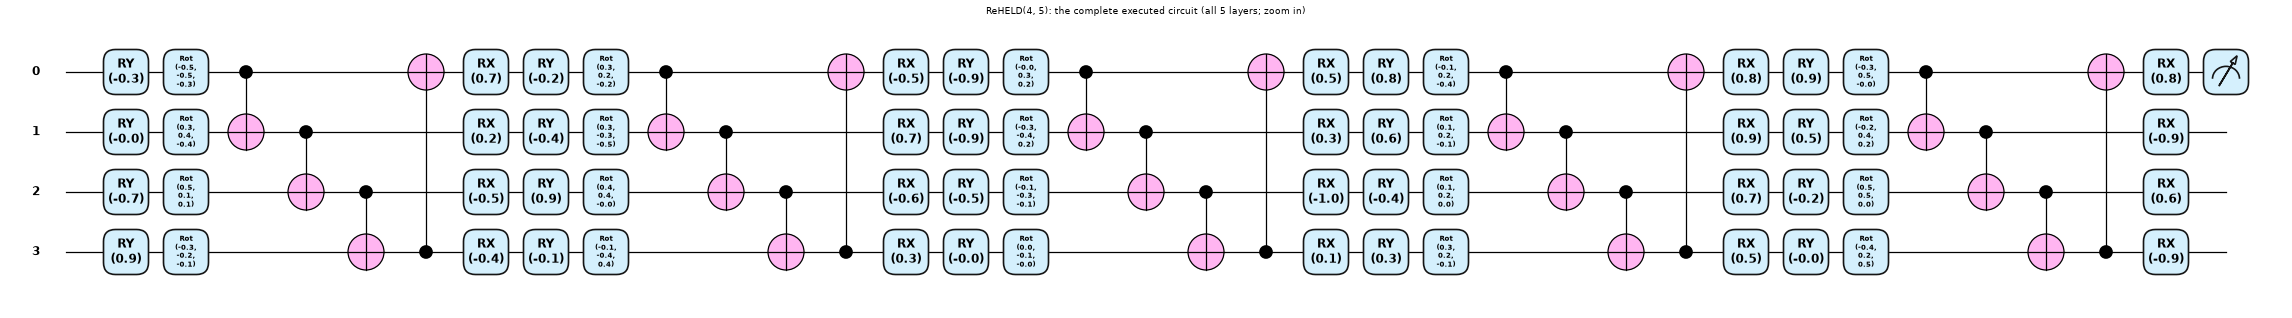

,qubits,layers,depth,gates,gate_counts,trainable_params
architecture,,,,,,
"HELD(1,1)",1,1,3,3,"{'RY': 1, 'Rot': 1, 'RX': 1}",7
"ReHELD(1,1)",1,1,3,3,"{'RY': 1, 'Rot': 1, 'RX': 1}",7
"HELD/ReHELD(4,5)",4,5,35,80,"{'RY': 20, 'Rot': 20, 'CNOT': 20, 'RX': 20}",140


In [11]:
# the large architecture: first two layers at a readable size, then the complete circuit
m2 = BIG_M
P2 = init_params(m2, 2, SEED, torch.float64); qn2 = qnode_factory(m2, 2, True)
fig, ax = qml.draw_mpl(qn2, decimals=1, style="pennylane")(x_example, *P2)
fig.suptitle(f"ReHELD({m2}, L): the first 2 layers of the large circuit (R: RY, G: Rot + CNOT ring, E: RX)", y=1.02, fontsize=11); plt.show()

PB = init_params(BIG_M, BIG_L, SEED, torch.float64); qnB = qnode_factory(BIG_M, BIG_L, True)
fig, ax = qml.draw_mpl(qnB, decimals=1, style="pennylane", fontsize=14)(x_example, *PB); fig.set_dpi(60)
fig.suptitle(f"ReHELD({BIG_M}, {BIG_L}): the complete executed circuit (all {BIG_L} layers; zoom in)", y=1.02, fontsize=11)
plt.show()
arch_rows.append(dict(architecture=f"HELD/ReHELD({BIG_M},{BIG_L})", **circuit_stats(qnB, (x_example, *PB), BIG_M, BIG_L)))
display(pd.DataFrame(arch_rows).set_index("architecture"))

**Assumptions where the paper omits circuit details** (all `# CHOICE:`): the gate order inside a layer (RY, Rot, CNOT ring, RX), the use of one trainable 2-vector `w` per qubit, block and layer (so every qubit sees a different
linear or sine-squashed combination of the two input features), the CNOT ring as the entangler, the single-qubit readout `<Z_0>`, and the random initialisation. The circuit is noiseless and exact, as in the paper's simulations.

**Equivalence of the two implementations.** The assertion below compares the fast simulator against the PennyLane QNode for random parameters (float64). It is repeated later for every trained model.

In [12]:
def assert_equivalent(m, L, nl, Pf, X, atol=1e-5, tag=""):
    # Pf: parameters (float32 or float64). QNode and fast simulator are both evaluated in float64 on the same numbers.
    P64 = [p.detach().double() for p in Pf]; Xb = torch.tensor(X, dtype=torch.float64)
    with torch.no_grad():
        a = forward_fast(Xb, *P64, m, L, nl).numpy()
        b = qnode_factory(m, L, nl)(Xb, *P64).numpy()
    err = float(np.abs(a - b).max())
    assert err < atol, f"simulator and QNode differ by {err} ({tag})"
    return err

rows = []
for (m, L, nl) in [(SMALL_M, SMALL_L, False), (SMALL_M, SMALL_L, True), (2, 2, True), (3, 2, False), (BIG_M, BIG_L, False), (BIG_M, BIG_L, True)]:
    g = torch.Generator().manual_seed(7)
    P = [torch.randn(L, m, 2, generator=g, dtype=torch.float64) * 2, torch.randn(L, m, 2, generator=g, dtype=torch.float64) * 2, torch.rand(L, m, 3, generator=g, dtype=torch.float64) * 6.28]
    rows.append(dict(qubits=m, layers=L, encoding="sin(-x^T w)" if nl else "x^T w", max_abs_diff=assert_equivalent(m, L, nl, P, X_te[:24], tag=f"{(m, L, nl)}")))
display(pd.DataFrame(rows)); print("fast simulator == PennyLane QNode for random parameters (assertions passed)")

,qubits,layers,encoding,max_abs_diff
0,1,1,x^T w,0.000000e+00
1,1,1,sin(-x^T w),0.000000e+00
2,2,2,sin(-x^T w),5.551115e-16
3,3,2,x^T w,7.771561e-16
4,4,5,x^T w,1.110223e-15
5,4,5,sin(-x^T w),7.216450e-16


fast simulator == PennyLane QNode for random parameters (assertions passed)


## 4. Checking the Fourier-series claim (Eq. 14, claim C7)

Section III of the paper proves that the circuit output is a Fourier-type sum of the encoded data: `y(x) = sum_a c_a exp(i a . x_hat)`. For gates `RX(x_hat)` and `RY(x_hat)` the generator `-X/2` or `-Y/2` has the eigenvalues `+-1/2`, so
every encoding angle can only contribute the frequencies `-1, 0, +1`. With `n_enc = 2 m L` encoding angles `x_hat_1 ... x_hat_n` the output must therefore be exactly a combination of the `3^n` exponentials
`exp(i a . x_hat)`, `a` in `{-1, 0, 1}^n` (here `x_hat = x^T w` for HELD and `sin(-x^T w)` for ReHELD). We test this numerically: fit the coefficients `c_a` by linear least squares on random inputs and
look at the largest residual. A **negative control** removes the frequency `+1` from the basis; the residual must then become large, which shows the test can fail.

In [13]:
import itertools
def fourier_residual(m, L, nl, seed, n=500, allowed=(-1, 0, 1)):
    g = torch.Generator().manual_seed(seed)
    Wr = torch.randn(L, m, 2, generator=g, dtype=torch.float64) * 1.5; We = torch.randn(L, m, 2, generator=g, dtype=torch.float64) * 1.5
    th = torch.rand(L, m, 3, generator=g, dtype=torch.float64) * 6.28
    x = torch.rand(n, 2, generator=g, dtype=torch.float64) * 2 - 1
    y = forward_fast(x, Wr, We, th, m, L, nl).numpy()
    ar = torch.einsum("bk,lqk->blq", x, Wr).reshape(n, -1); ae = torch.einsum("bk,lqk->blq", x, We).reshape(n, -1)
    ghat = torch.cat([ar, ae], 1); ghat = torch.sin(-ghat) if nl else ghat                  # encoded angles x_hat
    freqs = np.array(list(itertools.product(allowed, repeat=ghat.shape[1])), dtype=float)   # (3^n, n)
    A = np.exp(1j * ghat.numpy() @ freqs.T)
    c, *_ = np.linalg.lstsq(A, y.astype(complex), rcond=None)
    return float(np.abs(A @ c - y).max()), len(freqs)

rows = []
for (m, L) in [(1, 1), (2, 1), (1, 2)]:
    for nl in (False, True):
        r_ok, K = fourier_residual(m, L, nl, seed=3)
        r_bad, _ = fourier_residual(m, L, nl, seed=3, allowed=(-1, 0))
        rows.append(dict(circuit=f"({m},{L})", encoding="ReHELD sin(-x^T w)" if nl else "HELD x^T w", n_exponentials=K, residual_full_spectrum=r_ok, residual_control_without_freq_plus1=r_bad))
fres = pd.DataFrame(rows); display(fres)
FOURIER_OK = bool((fres.residual_full_spectrum < 1e-6).all() and (fres.residual_control_without_freq_plus1 > 1e-3).all())
print("Eq. 14 spectrum reproduced to machine precision, control fails as it should:", FOURIER_OK)

,circuit,encoding,n_exponentials,residual_full_spectrum,residual_control_without_freq_plus1
0,"(1,1)",HELD x^T w,9,8.920730e-16,0.543021
1,"(1,1)",ReHELD sin(-x^T w),9,1.119477e-15,0.325347
2,"(2,1)",HELD x^T w,81,1.765824e-14,0.154403
3,"(2,1)",ReHELD sin(-x^T w),81,5.459634e-15,0.095884
4,"(1,2)",HELD x^T w,81,2.560787e-14,0.416584
5,"(1,2)",ReHELD sin(-x^T w),81,1.075443e-14,0.166421


Eq. 14 spectrum reproduced to machine precision, control fails as it should: True


## 5. Training routine and metrics

One routine trains every quantum model: cross-entropy of `p = (1 + <Z_0>) / 2` against the stability label (label 1 = stable), plus `beta * mean(theta^2)` for ReHELD (Eq. 16), Adam with full-batch gradients. The training accuracy is measured on the
(attacked) training set the model is fitted to, the test accuracy on the clean test set. After training, the fast simulator is asserted equal to the PennyLane QNode on the trained parameters. The optional `adv_eps` argument is only used by the extension in section 10.

In [14]:
F32 = torch.float32
def prob_fn_quantum(params, m, L, nl):
    return lambda x: (1 + forward_fast(x, *params, m, L, nl)) / 2

def bce(p, y):
    p = p.clamp(1e-6, 1 - 1e-6)
    return -(y * torch.log(p) + (1 - y) * torch.log(1 - p)).mean()

def fgsm(prob, X, y, eps):
    x = X.clone().requires_grad_(True)
    loss = bce(prob(x), y) * len(y)
    (g,) = torch.autograd.grad(loss, x)
    return (x + eps * g.sign()).clamp(-1, 1).detach()

def acc_of(prob, X, y, bs=1500):
    with torch.no_grad():
        p = torch.cat([prob(X[i:i + bs]) for i in range(0, len(X), bs)])
    return float(((p > 0.5).numpy() == y).mean())

def fit(prob_builder, params, X, y, Xte, yte, epochs, lr=LR, th=None, beta=0.0, adv_eps=0.0, eval_every=EVAL_EVERY):
    # generic Adam trainer. prob_builder(params) -> function x -> P(stable). th: tensor penalised by beta * mean(th^2).
    opt = torch.optim.Adam(params, lr=lr)
    Xt, yt, Xe = torch.tensor(X, dtype=F32), torch.tensor(y, dtype=F32), torch.tensor(Xte, dtype=F32)
    hist, t0 = [], time.time()
    for ep in range(epochs):
        prob = prob_builder(params)
        if adv_eps > 0:                                              # extension: adversarial training with FGSM against the current model
            Xa = fgsm(prob, Xt, yt, adv_eps); Xin, yin = torch.cat([Xt, Xa]), torch.cat([yt, yt])
        else:
            Xin, yin = Xt, yt
        opt.zero_grad()
        p = prob(Xin)
        loss = bce(p, yin) + (beta * (th ** 2).mean() if (th is not None and beta > 0) else 0.0)
        loss.backward(); opt.step()
        with torch.no_grad():
            tr = float(((p[:len(yt)] > 0.5).float() == yt).float().mean())
        if ep % eval_every == 0 or ep == epochs - 1:
            hist.append((ep + 1, tr, acc_of(prob_builder(params), Xe, yte)))
    out = dict(params=[q.detach() for q in params], hist=np.array(hist), seconds=time.time() - t0)
    pf = prob_builder(params)
    out["train_acc"], out["test_acc"] = acc_of(pf, Xt, y), acc_of(pf, Xe, yte)
    return out

RUNS = {}        # (experiment, model, seed) -> result dict
ROWS = []        # flat table of results
def run_quantum(exp, model, m, L, nl, beta, X, y, epochs, seed, attack, check=False):
    P = [p.clone().requires_grad_() for p in init_params(m, L, seed)]
    res = fit(lambda ps: prob_fn_quantum(ps, m, L, nl), P, X, y, X_te, y_te, epochs, th=P[2], beta=beta)
    res.update(spec=dict(m=m, L=L, nl=nl, beta=beta))
    if check:
        res["sim_vs_qnode"] = assert_equivalent(m, L, nl, res["params"], X_te[:12], tag=f"{exp}/{model}/{seed}")
    RUNS[(exp, model, seed)] = res
    ROWS.append(dict(experiment=exp, model=model, attack=attack, seed=seed, train_acc=res["train_acc"], test_acc=res["test_acc"], seconds=res["seconds"]))
    print(f"  {exp:<16}{model:<22}seed {seed}: train acc {res['train_acc']:.3f} | clean test acc {res['test_acc']:.3f} | {res['seconds']:.0f} s")
    return res

def attacked_sets(seed):
    r = np.random.default_rng(seed)
    return delete_attack(X_tr, y_tr, DELETE_FRAC, r), poison_attack(X_tr, y_tr, POISON_REL, r)

def metrics_block(prob, X, y):
    with torch.no_grad(): pred = (prob(torch.tensor(X, dtype=F32)) > 0.5).numpy().astype(int)
    # unstable (0) is the event to detect, so it is the "positive" class for precision / recall / F1
    return dict(accuracy=(pred == y).mean(), precision_unstable=precision_score(y, pred, pos_label=0, zero_division=0),
                recall_unstable=recall_score(y, pred, pos_label=0, zero_division=0), f1_unstable=f1_score(y, pred, pos_label=0, zero_division=0)), pred
print("trainer ready")

trainer ready


## 6. Experiment A: encoding function under the deletion attack (paper Fig. 3, claims C1 and C2)

The smallest circuits isolate the effect of the data encoding: **HELD(1,1)** with the linear `g(x) = x^T w` and **ReHELD(1,1)** with `g(x) = sin(-x^T w)`, both trained on the 15 % of the training pool that survives the deletion attack and tested on the clean
test set. To isolate the encoding, ReHELD(1,1) is trained here **without** the regulariser (`beta = 0`); the regulariser is studied separately in section 8. All seeds draw their own deletion subset and initialisation.

In [15]:
print("Experiment A: deletion attack, 1 qubit x 1 layer")
for seed in SEEDS_SMALL:
    (Xd, yd), _ = attacked_sets(seed)
    run_quantum("A_fig3", "HELD(1,1)", SMALL_M, SMALL_L, False, 0.0, Xd, yd, EP_FIG3, seed, "deletion", check=True)
    run_quantum("A_fig3", "ReHELD(1,1) beta=0", SMALL_M, SMALL_L, True, 0.0, Xd, yd, EP_FIG3, seed, "deletion", check=True)
dfA = pd.DataFrame([r for r in ROWS if r["experiment"] == "A_fig3"])
display(dfA.groupby("model")[["train_acc", "test_acc"]].agg(["mean", "std"]).round(4))

Experiment A: deletion attack, 1 qubit x 1 layer


  A_fig3          HELD(1,1)             seed 42: train acc 0.978 | clean test acc 0.904 | 8 s


  A_fig3          ReHELD(1,1) beta=0    seed 42: train acc 0.956 | clean test acc 0.878 | 6 s


  A_fig3          HELD(1,1)             seed 43: train acc 0.822 | clean test acc 0.892 | 5 s


  A_fig3          ReHELD(1,1) beta=0    seed 43: train acc 0.867 | clean test acc 0.886 | 5 s


train_acc         test_acc        
                        mean     std     mean     std
model                                                
HELD(1,1)             0.9000  0.1100    0.898  0.0085
ReHELD(1,1) beta=0    0.9111  0.0629    0.882  0.0057

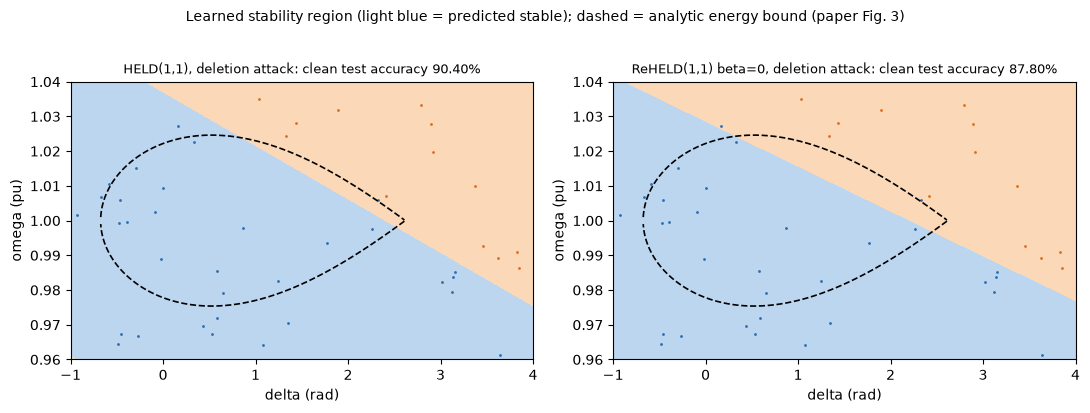

In [16]:
def plot_region(ax, res, X, y, title, resolution=(70, 45)):
    m, L, nl = res["spec"]["m"], res["spec"]["L"], res["spec"]["nl"]
    dd, ww = np.meshgrid(np.linspace(*DELTA_RANGE, resolution[0]), np.linspace(*OMEGA_RANGE, resolution[1]))
    G = to_model_input(dd.ravel(), ww.ravel())
    with torch.no_grad(): p = ((1 + forward_fast(torch.tensor(G, dtype=F32), *res["params"], m, L, nl)) / 2).numpy().reshape(dd.shape)
    ax.contourf(dd, ww, p, levels=[0, 0.5, 1], colors=["#fbd9b8", "#bcd6f0"])
    dp, wp = to_physical(X)
    ax.scatter(dp[y == 0], wp[y == 0], s=4, c=C_UNSTABLE, linewidths=0); ax.scatter(dp[y == 1], wp[y == 1], s=4, c=C_STABLE, linewidths=0)
    energy_bound_contour(ax); ax.set_title(title, fontsize=9); ax.set_xlabel("delta (rad)"); ax.set_ylabel("omega (pu)")

s0 = SEEDS_SMALL[0]; (Xd0, yd0), (Xp0, yp0) = attacked_sets(s0)
fig, axs = plt.subplots(1, 2, figsize=(11, 4))
for ax, name in zip(axs, ["HELD(1,1)", "ReHELD(1,1) beta=0"]):
    r = RUNS[("A_fig3", name, s0)]; plot_region(ax, r, Xd0, yd0, f"{name}, deletion attack: clean test accuracy {r['test_acc']:.2%}")
plt.suptitle("Learned stability region (light blue = predicted stable); dashed = analytic energy bound (paper Fig. 3)", y=1.02, fontsize=10); plt.tight_layout(); plt.show()

## 7. Experiments B and C: the large circuit under the deletion and poisoning attacks (paper Fig. 5 and Fig. 6, claims C4 and C5)

Both attacks are applied to the training pool and the large circuit (paper: 6 qubits, 15 layers; `FAST_MODE`: smaller) is trained as **HELD** (linear encoding, no regulariser) and as **ReHELD** (`sin(-x^T w)` encoding and `beta = 10`).
The poisoning experiment additionally trains ReHELD with `beta = 0` for the paper's Fig. 4 comparison (section 8). Test accuracy is on the clean test set.

In [17]:
print(f"Experiment B: deletion attack, circuit ({BIG_M},{BIG_L}), {EP_DELETE} epochs")
for i, seed in enumerate(SEEDS_BIG):
    (Xd, yd), _ = attacked_sets(seed)
    run_quantum("B_fig5_delete", "HELD", BIG_M, BIG_L, False, 0.0, Xd, yd, EP_DELETE, seed, "deletion", check=(i == 0))
    run_quantum("B_fig5_delete", "ReHELD beta=10", BIG_M, BIG_L, True, BETA, Xd, yd, EP_DELETE, seed, "deletion", check=(i == 0))

Experiment B: deletion attack, circuit (4,5), 150 epochs


  B_fig5_delete   HELD                  seed 42: train acc 1.000 | clean test acc 0.904 | 36 s


  B_fig5_delete   ReHELD beta=10        seed 42: train acc 1.000 | clean test acc 0.902 | 103 s


In [18]:
print(f"Experiment C: poisoning attack, circuit ({BIG_M},{BIG_L}), {EP_POISON} epochs")
for i, seed in enumerate(SEEDS_BIG):
    _, (Xp, yp) = attacked_sets(seed)
    run_quantum("C_fig6_poison", "HELD", BIG_M, BIG_L, False, 0.0, Xp, yp, EP_POISON, seed, "poisoning", check=(i == 0))
    run_quantum("C_fig6_poison", "ReHELD beta=10", BIG_M, BIG_L, True, BETA, Xp, yp, EP_POISON, seed, "poisoning", check=(i == 0))
    run_quantum("C_fig6_poison", "ReHELD beta=0", BIG_M, BIG_L, True, 0.0, Xp, yp, EP_POISON, seed, "poisoning", check=(i == 0))

Experiment C: poisoning attack, circuit (4,5), 100 epochs


  C_fig6_poison   HELD                  seed 42: train acc 0.943 | clean test acc 0.962 | 131 s


  C_fig6_poison   ReHELD beta=10        seed 42: train acc 0.940 | clean test acc 0.954 | 162 s


  C_fig6_poison   ReHELD beta=0         seed 42: train acc 0.947 | clean test acc 0.958 | 179 s


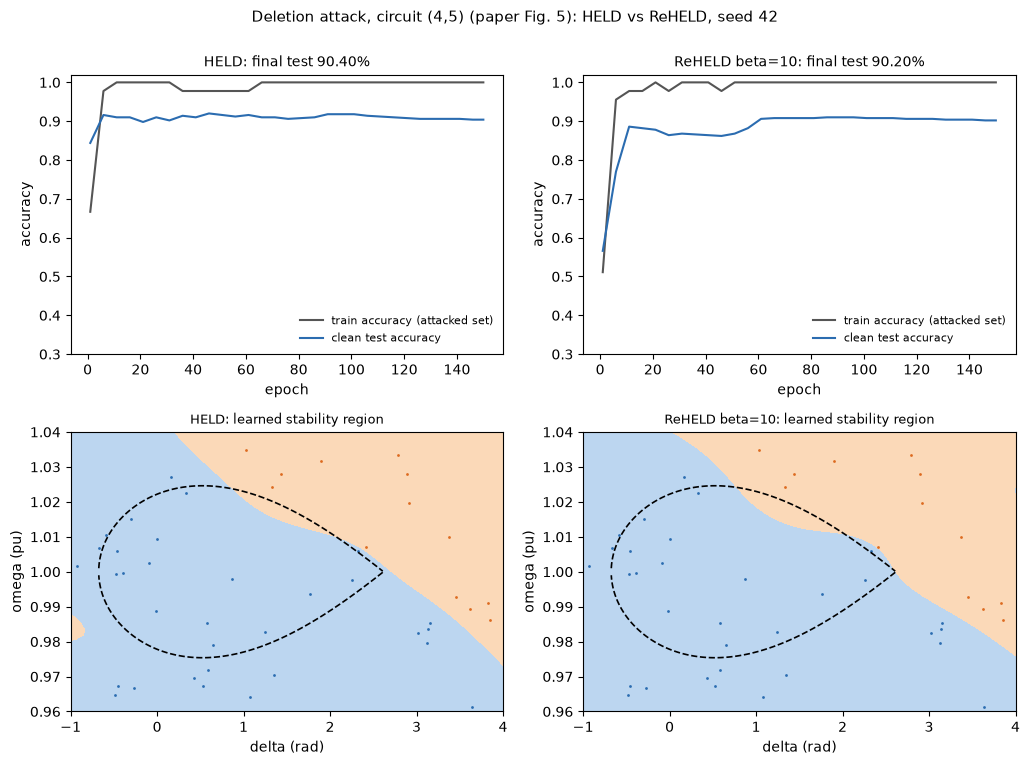

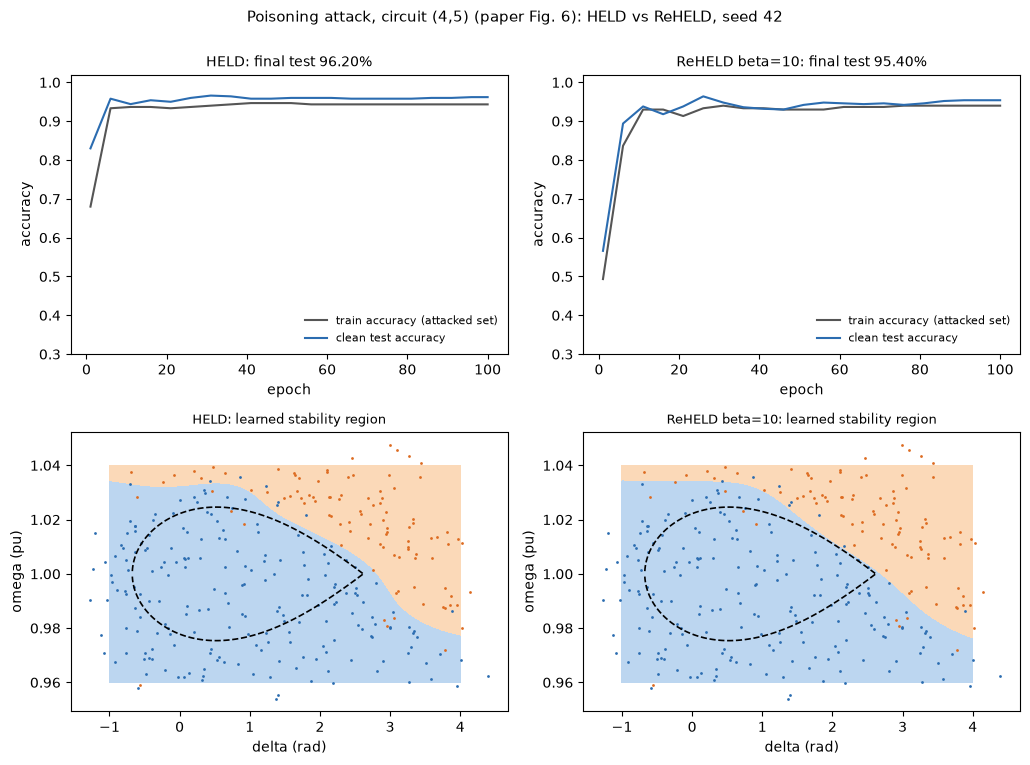

In [19]:
def curves(exp, names, seed, title):
    fig, axs = plt.subplots(2, len(names), figsize=(5.2 * len(names), 7.6))
    for j, name in enumerate(names):
        r = RUNS[(exp, name, seed)]; h = r["hist"]
        axs[0, j].plot(h[:, 0], h[:, 1], label="train accuracy (attacked set)", color="#555"); axs[0, j].plot(h[:, 0], h[:, 2], label="clean test accuracy", color=C_STABLE)
        axs[0, j].set_ylim(0.3, 1.02); axs[0, j].set_xlabel("epoch"); axs[0, j].set_ylabel("accuracy"); axs[0, j].set_title(f"{name}: final test {r['test_acc']:.2%}", fontsize=10); axs[0, j].legend(frameon=False, fontsize=8, loc="lower right")
        Xa = (attacked_sets(seed)[0] if "delete" in exp else attacked_sets(seed)[1])
        plot_region(axs[1, j], r, Xa[0], Xa[1], f"{name}: learned stability region")
    plt.suptitle(title, y=1.0, fontsize=11); plt.tight_layout(); plt.show()

sB = SEEDS_BIG[0]
curves("B_fig5_delete", ["HELD", "ReHELD beta=10"], sB, f"Deletion attack, circuit ({BIG_M},{BIG_L}) (paper Fig. 5): HELD vs ReHELD, seed {sB}")
curves("C_fig6_poison", ["HELD", "ReHELD beta=10"], sB, f"Poisoning attack, circuit ({BIG_M},{BIG_L}) (paper Fig. 6): HELD vs ReHELD, seed {sB}")

## 8. Experiment D: the regularisation weight (paper Fig. 4, claim C3)

Paper: under the poisoning attack ReHELD trained with `beta = 10` beats `beta = 0` by nearly 4 points, and the learned variational angles are more concentrated around 0 (Fig. 4c), which the Fourier analysis reads as smaller frequency amplitudes `alpha`.
We reuse the poisoning runs of section 7 (`beta = 10` and `beta = 0`, same data, same initialisation) and compare accuracy curves and the distribution of the variational angles.

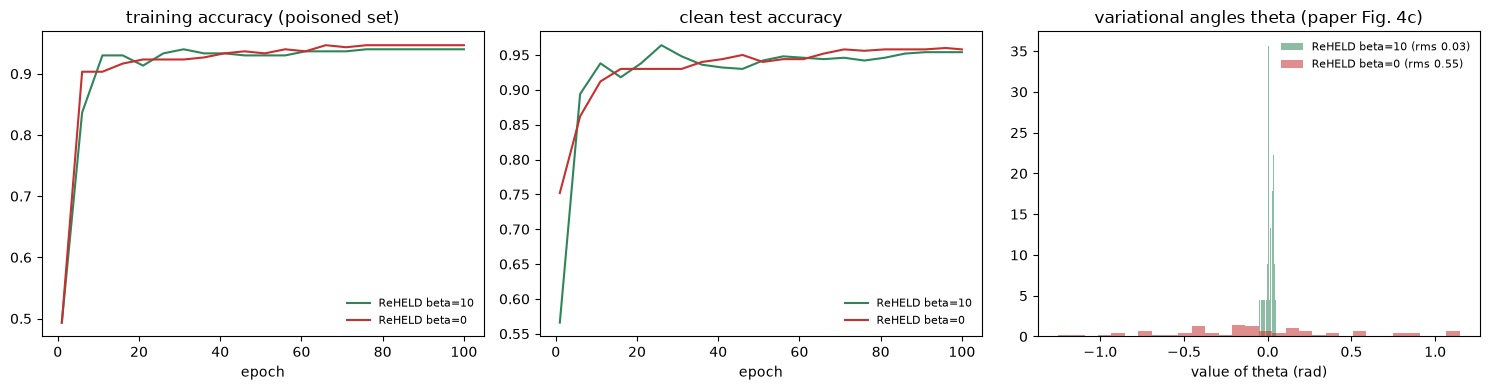

train_acc     test_acc    
                    mean std     mean std
model                                    
ReHELD beta=0     0.9467 NaN    0.958 NaN
ReHELD beta=10    0.9400 NaN    0.954 NaN

In [20]:
fig, axs = plt.subplots(1, 3, figsize=(15, 4))
for name, col in [("ReHELD beta=10", "#2f855a"), ("ReHELD beta=0", "#c53030")]:
    r = RUNS[("C_fig6_poison", name, sB)]; h = r["hist"]
    axs[0].plot(h[:, 0], h[:, 1], color=col, label=name); axs[1].plot(h[:, 0], h[:, 2], color=col, label=name)
    axs[2].hist(r["params"][2].numpy().ravel(), bins=30, alpha=0.55, color=col, label=f"{name} (rms {r['params'][2].pow(2).mean().sqrt().item():.2f})", density=True)
axs[0].set_title("training accuracy (poisoned set)"); axs[1].set_title("clean test accuracy"); axs[2].set_title("variational angles theta (paper Fig. 4c)")
for a in axs[:2]: a.set_xlabel("epoch"); a.legend(frameon=False, fontsize=8)
axs[2].set_xlabel("value of theta (rad)"); axs[2].legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.show()
dfD = pd.DataFrame([r for r in ROWS if r["experiment"] == "C_fig6_poison" and r["model"].startswith("ReHELD")])
display(dfD.groupby("model")[["train_acc", "test_acc"]].agg(["mean", "std"]).round(4))

## 9. References without the attack, and classical baselines

*Quantum reference.* The same circuits trained on the **clean** training pool (one seed) show how much accuracy the attacks cost and whether the circuit is expressive enough at this size.
*Classical baselines on identical inputs* (the paper has none): an RBF-SVC, a random forest and a small MLP, trained on the same attacked training sets in the same `[-1, 1]^2` inputs and tested on the same clean test set. They use default hyper-parameters
(`# CHOICE:` `C = 1`, 200 trees, MLP with two hidden layers of 16 units), with no tuning on the test set.

In [21]:
print(f"Reference without attack, circuit ({BIG_M},{BIG_L}), {EP_CLEAN} epochs (first seed only)")
run_quantum("E_clean", "HELD", BIG_M, BIG_L, False, 0.0, X_tr, y_tr, EP_CLEAN, SEEDS_BIG[0], "none")
run_quantum("E_clean", "ReHELD beta=10", BIG_M, BIG_L, True, BETA, X_tr, y_tr, EP_CLEAN, SEEDS_BIG[0], "none")
print("Reference without attack, circuit (1,1)")
run_quantum("E_clean", "HELD(1,1)", SMALL_M, SMALL_L, False, 0.0, X_tr, y_tr, EP_FIG3, SEEDS_SMALL[0], "none")
run_quantum("E_clean", "ReHELD(1,1) beta=0", SMALL_M, SMALL_L, True, 0.0, X_tr, y_tr, EP_FIG3, SEEDS_SMALL[0], "none")

print("Classical baselines")
BASE = []
for seed in SEEDS_SMALL:
    (Xd, yd), (Xp, yp) = attacked_sets(seed)
    for attack, (Xa, ya) in {"none": (X_tr, y_tr), "deletion": (Xd, yd), "poisoning": (Xp, yp)}.items():
        for name, mk in {"SVC (RBF)": lambda: SVC(kernel="rbf", C=1.0, gamma="scale"),
                         "RandomForest": lambda: RandomForestClassifier(n_estimators=200, random_state=seed, n_jobs=1),
                         "MLP 16-16": lambda: MLPClassifier(hidden_layer_sizes=(16, 16), max_iter=1500, random_state=seed)}.items():
            t0 = time.time(); clf = mk().fit(Xa, ya)
            BASE.append(dict(model=name, attack=attack, seed=seed, train_acc=clf.score(Xa, ya), test_acc=clf.score(X_te, y_te), seconds=time.time() - t0))
dfBase = pd.DataFrame(BASE)
display(dfBase.groupby(["attack", "model"])[["train_acc", "test_acc"]].agg(["mean", "std"]).round(4))

Reference without attack, circuit (4,5), 60 epochs (first seed only)


  E_clean         HELD                  seed 42: train acc 0.980 | clean test acc 0.954 | 92 s


  E_clean         ReHELD beta=10        seed 42: train acc 0.950 | clean test acc 0.924 | 97 s
Reference without attack, circuit (1,1)


  E_clean         HELD(1,1)             seed 42: train acc 0.933 | clean test acc 0.912 | 141 s


  E_clean         ReHELD(1,1) beta=0    seed 42: train acc 0.933 | clean test acc 0.904 | 173 s
Classical baselines


train_acc         test_acc        
                            mean     std     mean     std
attack    model                                          
deletion  MLP 16-16       0.9889  0.0157    0.937  0.0325
          RandomForest    1.0000  0.0000    0.892  0.0424
          SVC (RBF)       0.9444  0.0471    0.905  0.0354
none      MLP 16-16       0.9950  0.0024    0.971  0.0014
          RandomForest    1.0000  0.0000    0.965  0.0014
          SVC (RBF)       0.9767  0.0000    0.952  0.0000
poisoning MLP 16-16       0.9417  0.0071    0.955  0.0071
          RandomForest    1.0000  0.0000    0.943  0.0184
          SVC (RBF)       0.9417  0.0024    0.950  0.0057

## 10. Extension beyond the paper: a test-time (FGSM) adversarial attack and adversarial training

The paper's two attacks corrupt the *training* data. The more common meaning of "adversarial attack" in machine learning is an *evasion* attack at test time, and the standard defence is **adversarial training**. This section is **not part of the paper**: it asks the same question of the
HELD and ReHELD circuits and of a small classical MLP. A white-box **FGSM** attacker moves every clean test state by `eps = 0.10` (5 % of the input span, in the `[-1, 1]` scale) in the direction that increases the loss; **adversarial training** trains on the clean samples plus FGSM samples crafted against the current model at every step.
A small circuit (`EXT_M` qubits, `EXT_L` layers) keeps the cost low; all models see the same clean training pool.

Extension: clean training pool, circuit (2,2), 60 epochs, FGSM eps = 0.1


clean_acc     fgsm_acc    
                                 mean std     mean std
model                                                 
HELD (adv-trained)              0.920 NaN    0.794 NaN
HELD (standard)                 0.912 NaN    0.788 NaN
MLP 16-16 (adv-trained)         0.950 NaN    0.792 NaN
MLP 16-16 (standard)            0.960 NaN    0.794 NaN
ReHELD beta=1 (adv-trained)     0.932 NaN    0.788 NaN
ReHELD beta=1 (standard)        0.926 NaN    0.798 NaN

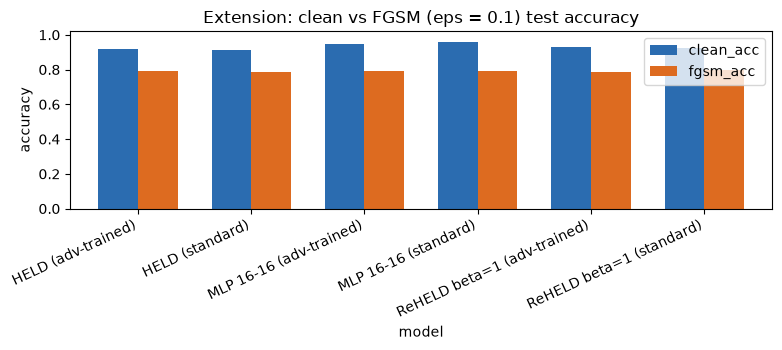

In [22]:
EXT = []
Xt_e, yt_e = torch.tensor(X_te, dtype=F32), torch.tensor(y_te, dtype=F32)
class TinyMLP(torch.nn.Module):
    def __init__(s, seed):
        super().__init__(); torch.manual_seed(seed); s.net = torch.nn.Sequential(torch.nn.Linear(2, 16), torch.nn.Tanh(), torch.nn.Linear(16, 16), torch.nn.Tanh(), torch.nn.Linear(16, 1))
    def forward(s, x): return torch.sigmoid(s.net(x)).squeeze(-1)

EM, EL = EXT_M, EXT_L
print(f"Extension: clean training pool, circuit ({EM},{EL}), {EP_EXT} epochs, FGSM eps = {FGSM_EPS}")
for seed in SEEDS_EXT:
    for tag, adv in [("standard", 0.0), ("adv-trained", FGSM_EPS)]:
        for name, nl, beta in [("HELD", False, 0.0), ("ReHELD beta=1", True, 1.0)]:
            P = [p.clone().requires_grad_() for p in init_params(EM, EL, seed)]
            res = fit(lambda ps, nl=nl: prob_fn_quantum(ps, EM, EL, nl), P, X_tr, y_tr, X_te, y_te, EP_EXT, th=P[2], beta=beta, adv_eps=adv)
            pr = prob_fn_quantum(res["params"], EM, EL, nl)
            EXT.append(dict(model=f"{name} ({tag})", seed=seed, clean_acc=res["test_acc"], fgsm_acc=acc_of(pr, fgsm(pr, Xt_e, yt_e, FGSM_EPS), y_te), seconds=res["seconds"]))
        net = TinyMLP(seed); res = fit(lambda ps: (lambda x: net(x)), list(net.parameters()), X_tr, y_tr, X_te, y_te, EP_EXT, adv_eps=adv)
        pr = lambda x: net(x)
        EXT.append(dict(model=f"MLP 16-16 ({tag})", seed=seed, clean_acc=res["test_acc"], fgsm_acc=acc_of(pr, fgsm(pr, Xt_e, yt_e, FGSM_EPS), y_te), seconds=res["seconds"]))
dfExt = pd.DataFrame(EXT)
display(dfExt.groupby("model")[["clean_acc", "fgsm_acc"]].agg(["mean", "std"]).round(4))
fig, ax = plt.subplots(figsize=(8, 3.6)); g = dfExt.groupby("model")[["clean_acc", "fgsm_acc"]].mean()
g.plot.bar(ax=ax, color=[C_STABLE, C_UNSTABLE], width=0.7); ax.set_ylabel("accuracy"); ax.set_ylim(0, 1.02); ax.set_title(f"Extension: clean vs FGSM (eps = {FGSM_EPS}) test accuracy"); plt.xticks(rotation=25, ha="right"); plt.tight_layout(); plt.show()

## 11. Metrics beyond accuracy: confusion matrices

Accuracy hides which kind of error a stability classifier makes. Missing an unstable case (predicting "stable") is the dangerous error. The matrices below are for the first seed of the large circuit under both attacks (clean test set, `unstable` = positive class).

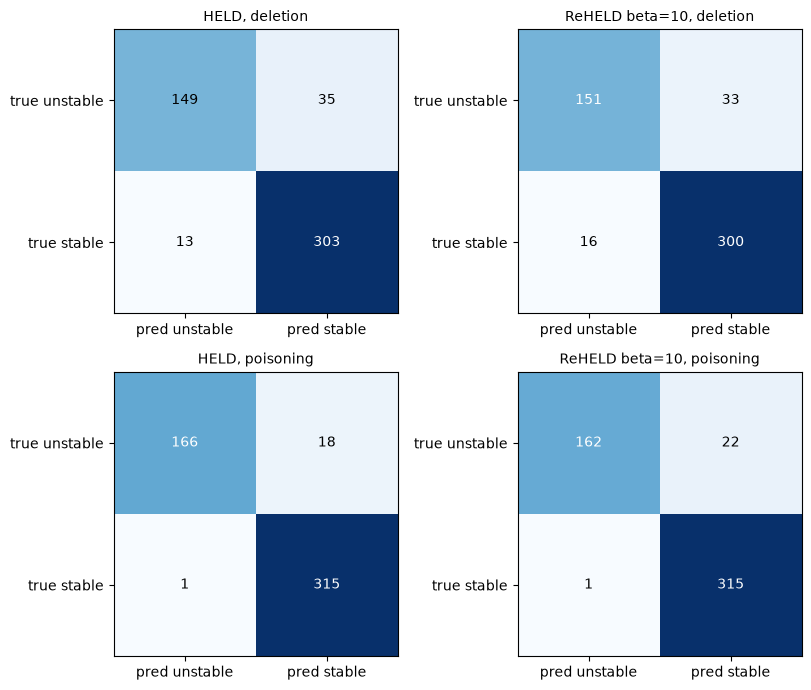

,attack,model,accuracy,precision_unstable,recall_unstable,f1_unstable
0,deletion,HELD,0.904,0.9198,0.8098,0.8613
1,deletion,ReHELD beta=10,0.902,0.9042,0.8207,0.8604
2,poisoning,HELD,0.962,0.9940,0.9022,0.9459
3,poisoning,ReHELD beta=10,0.954,0.9939,0.8804,0.9337


In [23]:
fig, axs = plt.subplots(2, 2, figsize=(8.5, 7)); mrows = []
for i, (exp, atk) in enumerate([("B_fig5_delete", "deletion"), ("C_fig6_poison", "poisoning")]):
    for j, name in enumerate(["HELD", "ReHELD beta=10"]):
        r = RUNS[(exp, name, sB)]; sp = r["spec"]
        prob = prob_fn_quantum(r["params"], sp["m"], sp["L"], sp["nl"]); mt, pred = metrics_block(prob, X_te, y_te)
        cm = confusion_matrix(y_te, pred, labels=[0, 1]); ax = axs[i, j]
        ax.imshow(cm, cmap="Blues"); ax.set_xticks([0, 1], ["pred unstable", "pred stable"]); ax.set_yticks([0, 1], ["true unstable", "true stable"])
        for a in range(2):
            for b in range(2): ax.text(b, a, cm[a, b], ha="center", va="center", color="black" if cm[a, b] < cm.max() / 2 else "white")
        ax.set_title(f"{name}, {atk}", fontsize=10); mrows.append(dict(attack=atk, model=name, **{k: round(float(v), 4) for k, v in mt.items()}))
plt.tight_layout(); plt.show(); display(pd.DataFrame(mrows))

## 12. Side by side with the paper: a verdict per claim

Rule: a numeric claim is **reproduced** if our mean is within 2 accuracy points of the paper's value, otherwise **not reached** (we are lower) or **exceeded** (we are higher); a qualitative claim is judged by the sign and size of the gap we measure.
Paper values for the figures are read off the plots and the text (approximate, "~").

In [24]:
def stat(exp, model, key="test_acc"):
    v = np.array([r[key] for r in ROWS if r["experiment"] == exp and r["model"] == model]); return float(v.mean()) * 100, float(v.std()) * 100, len(v)
def verdict_num(nb, paper, tol=2.0):
    return "reproduced" if abs(nb - paper) <= tol else ("exceeded" if nb > paper else "not reached")
def fmt(t): return f"{t[0]:.2f} +- {t[1]:.2f} (n={t[2]})"

A1, A2 = stat("A_fig3", "HELD(1,1)"), stat("A_fig3", "ReHELD(1,1) beta=0")
B1, B2 = stat("B_fig5_delete", "HELD"), stat("B_fig5_delete", "ReHELD beta=10")
B1t, B2t = stat("B_fig5_delete", "HELD", "train_acc"), stat("B_fig5_delete", "ReHELD beta=10", "train_acc")
C1, C2, C3 = stat("C_fig6_poison", "HELD"), stat("C_fig6_poison", "ReHELD beta=10"), stat("C_fig6_poison", "ReHELD beta=0")
C1t, C2t = stat("C_fig6_poison", "HELD", "train_acc"), stat("C_fig6_poison", "ReHELD beta=10", "train_acc")
rel_nb = (A2[0] / A1[0] - 1) * 100; rel_paper = (90.04 / 76.15 - 1) * 100
rel2_nb = (np.mean([B2[0] / B1[0], C2[0] / C1[0]]) - 1) * 100

comp = [
 ["C1", "Fig. 3a: HELD(1,1) test acc, deletion (%)", 76.15, fmt(A1), verdict_num(A1[0], 76.15)],
 ["C2", "Fig. 3b: ReHELD(1,1) test acc, deletion (%)", 90.04, fmt(A2), verdict_num(A2[0], 90.04)],
 ["C2b", "ReHELD(1,1) better than HELD(1,1) (gain in points)", 90.04 - 76.15, f"{A2[0] - A1[0]:+.2f}", "reproduced" if abs((A2[0] - A1[0]) - 13.89) <= 2 else ("exceeded" if (A2[0] - A1[0]) > 13.89 else "not reached")],
 ["C3", "Fig. 4: beta=10 minus beta=0, poisoning (points)", 4.0, f"{C2[0] - C3[0]:+.2f}", "reproduced" if abs((C2[0] - C3[0]) - 4.0) <= 2 else ("exceeded" if (C2[0] - C3[0]) > 4.0 else "not reached")],
 ["C4a", "Fig. 5: HELD test acc, deletion (%)", 95.0, fmt(B1), verdict_num(B1[0], 95.0)],
 ["C4b", "Fig. 5: ReHELD test acc, deletion (%)", 98.0, fmt(B2), verdict_num(B2[0], 98.0)],
 ["C4c", "Fig. 5: train acc 'nearly 100 %' (HELD / ReHELD)", 100.0, f"{B1t[0]:.1f} / {B2t[0]:.1f}", "reproduced" if min(B1t[0], B2t[0]) >= 98 else "not reached"],
 ["C5a", "Fig. 6: HELD test acc, poisoning (%)", 95.0, fmt(C1), verdict_num(C1[0], 95.0)],
 ["C5b", "Fig. 6: ReHELD test acc, poisoning (%)", 98.0, fmt(C2), verdict_num(C2[0], 98.0)],
 ["C5c", "Fig. 6: train acc on poisoned set below 80 %", "<80", f"{C1t[0]:.1f} / {C2t[0]:.1f}", "reproduced" if max(C1t[0], C2t[0]) < 80 else "not reached (our noise is milder)"],
 ["C6a", "Abstract: relative gain ReHELD vs HELD, Fig. 3 (%)", round(rel_paper, 1), f"{rel_nb:+.1f}", verdict_num(rel_nb, rel_paper, 4.0)],
 ["C6b", "Abstract: relative gain, large circuit (%)", 3.0, f"{rel2_nb:+.1f}", "reproduced" if abs(rel2_nb - 3.0) <= 2 else ("exceeded" if rel2_nb > 3.0 else "not reached")],
 ["C7", "Eq. 14 Fourier-type output (numerical check)", "theory", "residual < 1e-6, control fails" if FOURIER_OK else "check failed", "reproduced" if FOURIER_OK else "not reached"],
 ["C8", "Fig. 7: 8-microgrid, 277 buses, ReHELD ~98 %", 98.0, "not run", "cannot be checked"],
]
dfComp = pd.DataFrame(comp, columns=["claim", "what", "paper", "this notebook", "verdict"]); display(dfComp)
print("\nClassical baselines on the same attacked data (mean clean test accuracy, %):")
display((dfBase.groupby(["attack", "model"])["test_acc"].mean().unstack() * 100).round(2))
print(f"\nTotal notebook runtime: {(time.time() - NOTEBOOK_T0) / 60:.1f} min (FAST_MODE = {FAST_MODE})")

,claim,what,paper,this notebook,verdict
0,C1,"Fig. 3a: HELD(1,1) test acc, deletion (%)",76.15,89.80 +- 0.60 (n=2),exceeded
1,C2,"Fig. 3b: ReHELD(1,1) test acc, deletion (%)",90.04,88.20 +- 0.40 (n=2),reproduced
2,C2b,"ReHELD(1,1) better than HELD(1,1) (gain in points)",13.89,-1.60,not reached
3,C3,"Fig. 4: beta=10 minus beta=0, poisoning (points)",4.0,-0.40,not reached
4,C4a,"Fig. 5: HELD test acc, deletion (%)",95.0,90.40 +- 0.00 (n=1),not reached
5,C4b,"Fig. 5: ReHELD test acc, deletion (%)",98.0,90.20 +- 0.00 (n=1),not reached
6,C4c,Fig. 5: train acc 'nearly 100 %' (HELD / ReHELD),100.0,100.0 / 100.0,reproduced
7,C5a,"Fig. 6: HELD test acc, poisoning (%)",95.0,96.20 +- 0.00 (n=1),reproduced
8,C5b,"Fig. 6: ReHELD test acc, poisoning (%)",98.0,95.40 +- 0.00 (n=1),not reached
9,C5c,Fig. 6: train acc on poisoned set below 80 %,<80,94.3 / 94.0,not reached (our noise is milder)



Classical baselines on the same attacked data (mean clean test accuracy, %):


model,MLP 16-16,RandomForest,SVC (RBF)
attack,,,
deletion,93.7,89.2,90.5
none,97.1,96.5,95.2
poisoning,95.5,94.3,95.0



Total notebook runtime: 25.3 min (FAST_MODE = True)


## Reading the paper critically

* **What the committed (FAST_MODE) run shows.** The paper's claimed advantage of ReHELD over HELD was **not reproduced**: in the verdict table the gains are about zero or slightly negative (1-qubit: HELD 89.8 % vs ReHELD 88.2 %; (4,5) circuit: 90.4 % vs 90.2 % under deletion and 96.2 % vs 95.4 % under poisoning), the regulariser beta = 10 did not help (-0.4 points), and the 1-qubit HELD is far above the paper's 76 %. The theory check (Eq. 14) and the circuit equivalence assertions pass exactly. These numbers come from a reduced circuit and few steps, one seed for the large circuit and two for the small ones, so they cannot settle the question for the paper's (6,15) circuit; they only show that on our regenerated SMIB data the linear encoding is not the weak point.
* **The datasets are small and easy.** The SMIB state space is two-dimensional, the stability region is a single smooth blob, and a classical SVC or a tiny MLP reaches the same clean accuracy as the quantum circuits in the tables above. The comparison with classical models, which the paper does not make, shows that
  a quantum model is not needed for this task; the interesting question is only how the quantum model degrades.
* **The "attacks" are random, not adversarial.** Deleting 85 % of the training samples at random and adding Gaussian noise are data-quality problems; neither optimises anything against the model. The extension in section 10 shows that a real gradient-based evasion attack is a different threat, with different winners.
* **What "robustness" means here.** The claimed gain of ReHELD is measured as clean test accuracy after training on damaged data. It confounds two things: the bounded encoding (which changes what the circuit can represent) and the L2 penalty (which changes how it is trained). The paper's Fig. 3 isolates the encoding with the smallest possible circuit; we repeat that, and our result depends on how hard the 1-qubit task is for the linear encoding in the authors' data, which the paper does not state.
* **The theory explains less than it seems.** Eq. 14 is exact (we verified it to machine precision), but it holds for *every* re-uploading circuit with Pauli rotations; the step from "the encoded distribution has small variance" to "the circuit is more robust" is an argument, not a theorem. A smaller `x_hat` range does limit the effective frequencies, yet the same effect can be obtained classically by input scaling.
* **Missing details.** Data sizes, SMIB parameters, the attack's noise definition, optimiser and learning rate are not given, the code is not public, and the microgrid case (Fig. 7) rests on a 277-bus model of another paper. A faithful numerical match is therefore not possible, and a gap should not be read as a failure of the authors' method.
* **One system, simulated noiselessly.** All results are for an exact simulator. The paper motivates ReHELD with NISQ noise but does not run noisy simulations in this four-page version.

## Exercises

1. Change `POISON_REL` to 0.5 and to 1.0 (stronger noise) and rerun sections 2 and 7. When does the training accuracy fall below 80 % as in the paper's Fig. 6, and what happens to the clean test accuracy of HELD and ReHELD?
2. The paper's penalty is `beta * p^T p` on all parameters, here a mean over block G only. Switch the penalty to the sum over all parameters (`th` -> concatenation of all three tensors) and study how beta must be rescaled to keep training stable.
3. Replace the encoding `sin(-x^T w)` by `tanh(x^T w)` or by `x^T w` clipped to [-1, 1]. Does the Fourier check of section 4 still hold? Does the robustness gain survive?
4. Make the SMIB task harder: lower `DAMPING` to 2 or move `P_MECH` to 0.8 so the stability region becomes thin and curved. Repeat Experiment A: is the 1-qubit ReHELD still better than the 1-qubit HELD?
5. In section 10, increase `FGSM_EPS` to 0.2 and train the adversarially trained ReHELD for more epochs. Does adversarial training help the quantum circuit more or less than the MLP?